# DSC bolus residue and relative perfusion fields


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `dsc_bolus_residue_perfusion_fields` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：signal (1, 22, 128, 128, 80) int16：Original measured MRI intensities, ADU; axes batch,slice,row,column,time.；arterial_input (1, 80) float64：Author-supplied external arterial relaxation-rate proxy, s^-1; axes batch,time.；support (1, 22, 128, 128) bool：Input-only spatial support, dimensionless; axes batch,slice,row,column.。恢复目标：160lag流量加权残留体及相对flow/volume/transit time。

获取模型：GRE对数信号转浓度，外部AIF与flow-residue时间卷积形成组织曲线。实际恢复算法：main.reconstruct包含浓度转换和leakage修正；solvers.deconvolve作SVD/cSVD/oSVD截断逆。语义类型为 `inverse_spatial`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：数值方法参考，不能当作独立物理真值；test/validation.md:225是原始四场参考，不是患者灌注真值；AIF选择细节不可用。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：dsc_bolus_residue_perfusion_fields.ipynb单元1有保存图；t=np.arange(80)*1.55;ax[2].plot(t,raw['arterial_input'][0]);ax[2].set(xlabel='Time / s',ylabel='Arterial proxy / s⁻¹',title='Author-supplied arterial input')；dsc_bolus_residue_perfusion_fields.ipynb单元3有保存图；ax[0].plot(t,y[probes].T);ax[0].set(xlabel='Time / s',ylabel='Tissue proxy / s⁻¹',title='Eight fixed supported observations')；ax[1].imshow(convolution_matrix(a),origin='lower',aspe；dsc_bolus_residue_perfusion_fields.ipynb单元4：Results；dsc_bolus_residue_perfusion_fields.ipynb单元5有保存图；ax[0].axhline(0,color='gray',lw=.7);ax[0].legend();ax[0].set(xlabel='Lag / s',ylabel='Flow-scaled residue / s⁻¹',title='Fixed supported curve, all lags')；ax[1].hist(oi,bins=60);ax[；dsc_bolus_residue_perfusion_fields.ipynb单元6有保存图；fig,ax=plt.subplots(1,2,figsize=(11,4),layout='constrained');ax[0].plot(thresholds,sensitivity,'o-');ax[0].set(xlabel='OI limit',ylabel='Relative flow L2 change',title='Fresh whole。图/比较代码位于单元1, 3, 5, 6（从0计数）。代码单元4个，带execution_count的4个，保存PNG输出12幅；本审计未重新运行。

现有输出来自历史执行；本次未复跑。

限制与缺口：本次为静态语义与证据核查，未重新验证数值正确性或运行结果。

<!-- inverse-evidence-audit:20261026:end -->


## Problem
Recover the complete160-lag signed flow-scaled residue and three relative perfusion fields from a real22-slice80-frame gradient-echo bolus acquisition. This is susceptibility bolus convolution, distinct from ASL tagging or DCE exchange inference. No independently measured patient perfusion truth exists. Negative lobes and leakage-volume estimates remain in reconstruction and evaluation.

## Data
All128×128×22×80 original intensities, the supplied80-point arterial input and an input-only89588-voxel support are retained. The support derives from observed anatomy and strictly positive observed signal, before inversion; it is not an author segmentation or target fit. TE is25ms, TR1.55s, in-plane spacing1.796875mm and slice spacing4.3999996mm. Diagnosis, dose, scanner field strength and absolute relaxivity calibration are unavailable.


{'python': 'D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe', 'platform': 'Windows-10-10.0.26200-SP0', 'numpy': '2.4.6', 'scipy': '1.17.1', 'backend': 'inline'}
{'signal': ((1, 22, 128, 128, 80), 'int16'), 'arterial_input': ((1, 80), 'float64'), 'support': ((1, 22, 128, 128), 'bool')}


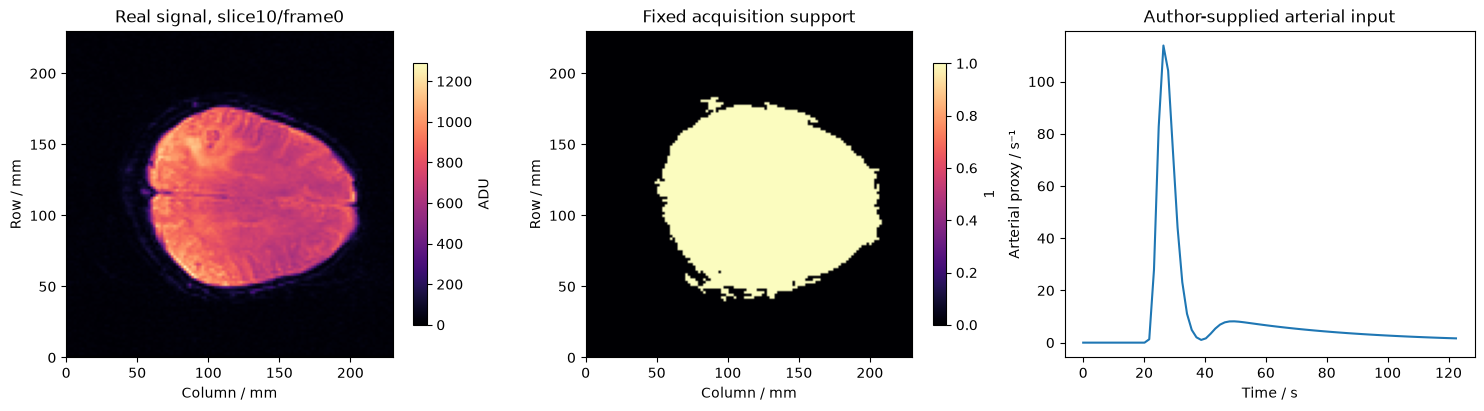

In [1]:
%matplotlib inline
import os,sys,time,json,hashlib,platform,gc
from pathlib import Path
import numpy as np, scipy, matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'data/raw_data.npz').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT));os.chdir(ROOT)
from src.main import reconstruct
from src.physics_model import convolution_matrix,forward
from src.solvers import deconvolve
from src.generate_data import perturb_concentration
from src.visualization import export_figure,image_panel
FIG=Path(os.environ.get('IMAGING_FIGURE_DIR',str(ROOT/'output/review_figures')))
records=[]
print(dict(python=sys.executable,platform=platform.platform(),numpy=np.__version__,scipy=scipy.__version__,backend=plt.get_backend()))
with np.load('data/raw_data.npz',allow_pickle=False) as z: raw={k:z[k] for k in z.files}
print({k:(v.shape,str(v.dtype)) for k,v in raw.items()})
fig,ax=plt.subplots(1,3,figsize=(15,4),layout='constrained')
image_panel(ax[0],raw['signal'][0,10,:,:,0],'Real signal, slice10/frame0','ADU')
image_panel(ax[1],raw['support'][0,10],'Fixed acquisition support','1')
t=np.arange(80)*1.55;ax[2].plot(t,raw['arterial_input'][0]);ax[2].set(xlabel='Time / s',ylabel='Arterial proxy / s⁻¹',title='Author-supplied arterial input')
records.append(export_figure(fig,FIG,'figure01_real_data',dict(signal_slice=raw['signal'][0,10,:,:,0],support_slice=raw['support'][0,10],time=t,aif=raw['arterial_input'][0]),'All raw data retained; one fixed slice shown. No patient-truth reference.'));plt.show()


## Physics
With measured signal $S$ and pre-bolus baseline $S_0$, the relaxation-rate proxy is $c=-\log(S/S_0)/T_E$ in inverse seconds. The tissue model is $c(t)=\int a(\tau)k(t-\tau)\,d\tau+e(t)$, where $a$ is the arterial proxy, $k=F R$ is the signed regularized flow-scaled residue and $e$ includes measurement/model error. Here $F$ is relative flow and $R$ the ideal retained tracer fraction. The recovered regularized $k$ is not constrained to be an ideal positive residue.

The source Simpson-smoothed discretization is $c\approx\Delta t\,Gk$. Circular methods pad80 observations to160 time samples. The full lag grid ends at246.45s and has248s periodic extent; the measured window ends at122.45s. The two different AIF endpoint conventions for causal and circular matrices are retained explicitly.

## Method
Compute the source slice-specific baseline with a5% mean-signal change rule, preserving its conservative count convention. For $G=U\Sigma V^T$, truncated inversion is $k=V\Sigma_\tau^+U^Tc/\Delta t$. sSVD uses20%, cSVD10%; oSVD tests5%,10%,...,95% and stops at the first oscillation index below0.035. The index is the sum of absolute second differences divided by160 times the signed maximum. Both the signed maximum and all160lags matter.

Relative volume integrates the tissue curve divided by arterial area. A two-regressor leakage model uses the mean nonenhancing curve and its negative time integral, with the source coefficient-of-variation gate. Transit time is corrected relative volume divided by flow. Source last11-point median/2-SD selection and global empty-slice baseline counts remain unchanged.

Independent tests demonstrated two upstream errors: an incorrect baseline slice stride and a missing oSVD inverse-time factor. Only those two lines were qualified before complete original reruns and local extraction. These are explicitly qualified results, not unchanged reproduction. Other paper/source discrepancies are documented in validation.


Complete fresh reconstruction seconds: 10.225904099992476


Fresh whole observations: {'svd': 0.2841115396372914, 'csvd': 0.24828614382379113, 'osvd': 0.29709020987553414} negative residue fractions: {'svd': 0.3452320623297763, 'csvd': 0.4754460000223244, 'osvd': 0.47467901672098944}


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_ncc": 0.9999999999999999,
    "reconstruction_nrmse": 4.791820829483389e-17,
    "relative_flow_ncc": 1.0000000000000002,
    "relative_flow_nrmse": 8.80434907933991e-17,
    "relative_volume_ncc": 1.0,
    "relative_volume_nrmse": 5.66932381471948e-17,
    "transit_time_ncc": 1.0,
    "transit_time_nrmse": 1.2740571448780819e-16,
    "forward_relative_l2": 0.2970902098755342
  },
  "thresholds": {
    "reconstruction_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "reconstruction_nrmse": {
      "comparison": "<=",
      "boundary": 1e-07
    },
    "relative_flow_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "relative_flow_nrmse": {
      "comparison": "<=",
      "boundary": 1e-07
    },
    "relative_volume_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "relative_volume_nrmse": {
      "comparison": "<=",
      "boundary": 1e-07
    }

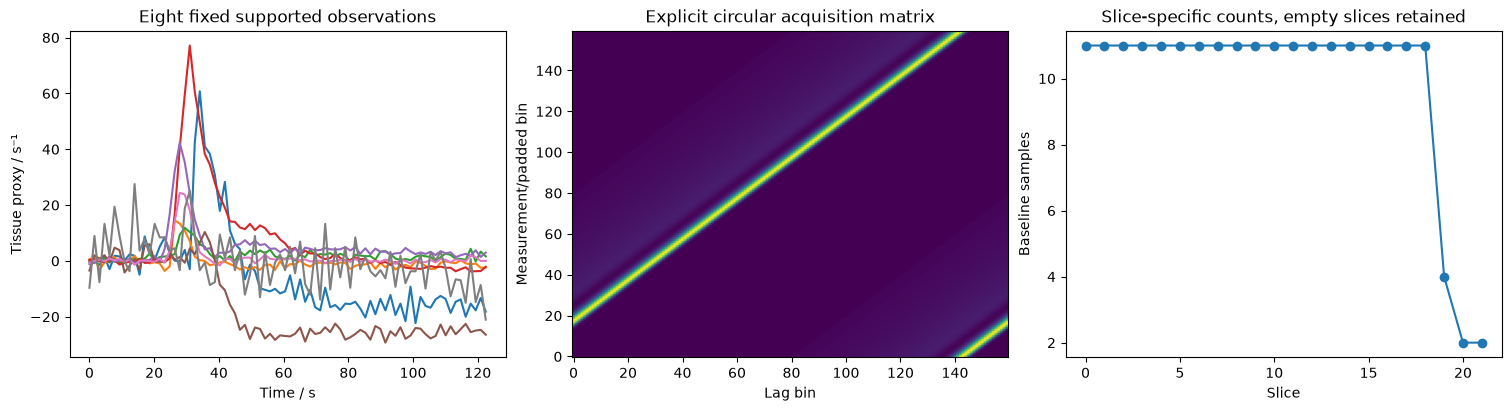

In [2]:
started=time.perf_counter()
submission,diagnostics=reconstruct(comparisons=True)
print('Complete fresh reconstruction seconds:',time.perf_counter()-started)
support=diagnostics['support'];y=diagnostics['concentration'][support];a=diagnostics['aif'];methods=diagnostics['methods']
coordinates=np.argwhere(support);probes=np.linspace(0,len(coordinates)-1,8,dtype=int)
maps={};curves={};forward_errors={};negative_fractions={}
for method,result in methods.items():
    field=np.zeros(support.shape);field[support]=result['map'];maps[method]=field
    curves[method]=result['residual'][probes].copy()
    prediction=forward(result['residual'],a,circulant=method!='svd')
    forward_errors[method]=float(np.linalg.norm(prediction-y)/np.linalg.norm(y))
    negative_fractions[method]=float(np.mean(result['residual']<0))
    if method=='osvd':
        observed_frame=np.zeros(support.shape);observed_frame[support]=y[:,17]
        predicted_frame=np.zeros(support.shape);predicted_frame[support]=prediction[:,17]
        residual_rms=np.zeros(support.shape);residual_rms[support]=np.sqrt(np.mean((prediction-y)**2,axis=1))
    del prediction
flow=submission['relative_flow'][0].copy();volume=submission['relative_volume'][0].copy();transit=submission['transit_time'][0].copy()
oi=methods['osvd']['oscillation'].copy();cutoffs=methods['osvd']['cutoff'].copy()
print('Fresh whole observations:',forward_errors,'negative residue fractions:',negative_fractions)
# Bounded-memory review: keep plotted fields/probes and public concentration, then release full submissions.
methods.clear();del submission;diagnostics.pop('concentration');gc.collect()
import importlib.util
spec=importlib.util.spec_from_file_location('independent_judge',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,exit_code=judge.evaluate(ROOT/'output/reconstruction.npz');assert exit_code==0,report
(ROOT/'output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf8');print(json.dumps(report,indent=2))
fig,ax=plt.subplots(1,3,figsize=(15,4),layout='constrained')
ax[0].plot(t,y[probes].T);ax[0].set(xlabel='Time / s',ylabel='Tissue proxy / s⁻¹',title='Eight fixed supported observations')
ax[1].imshow(convolution_matrix(a),origin='lower',aspect='auto');ax[1].set(xlabel='Lag bin',ylabel='Measurement/padded bin',title='Explicit circular acquisition matrix')
ax[2].plot(diagnostics['baseline_counts'],'o-');ax[2].set(xlabel='Slice',ylabel='Baseline samples',title='Slice-specific counts, empty slices retained')
records.append(export_figure(fig,FIG,'figure02_physics',dict(time=t,concentration_probes=y[probes],matrix=convolution_matrix(a),baseline_counts=diagnostics['baseline_counts']),'Complete local forward model; baseline-stride correction and physical time factor explained.'));plt.show()


## Results
Every displayed fresh reconstruction was computed above from the real raw data. The frozen qualified upstream measurements below were captured before extraction and are method references, never ground truth. The standalone evaluator scores all four full fields and the complete89588×80 supported observations, with no fitted alignment or scale. Empty support is explicitly zero; source outside-support0/0 sentinels do not enter the submission.


Whole-volume original versus fresh comparison table (dynamic-range NRMSE): {
  "svd_flow": 6.712733266701283e-17,
  "svd_transit": 1.3771242248856988e-16,
  "csvd_flow": 1.190328710896365e-16,
  "csvd_transit": 1.368790495415194e-16,
  "osvd_flow": 8.80434907933991e-17,
  "osvd_transit": 1.2740571448780819e-16,
  "leakage_volume": 5.66932381471948e-17,
  "uncorrected_volume": 7.26576533476523e-18
}


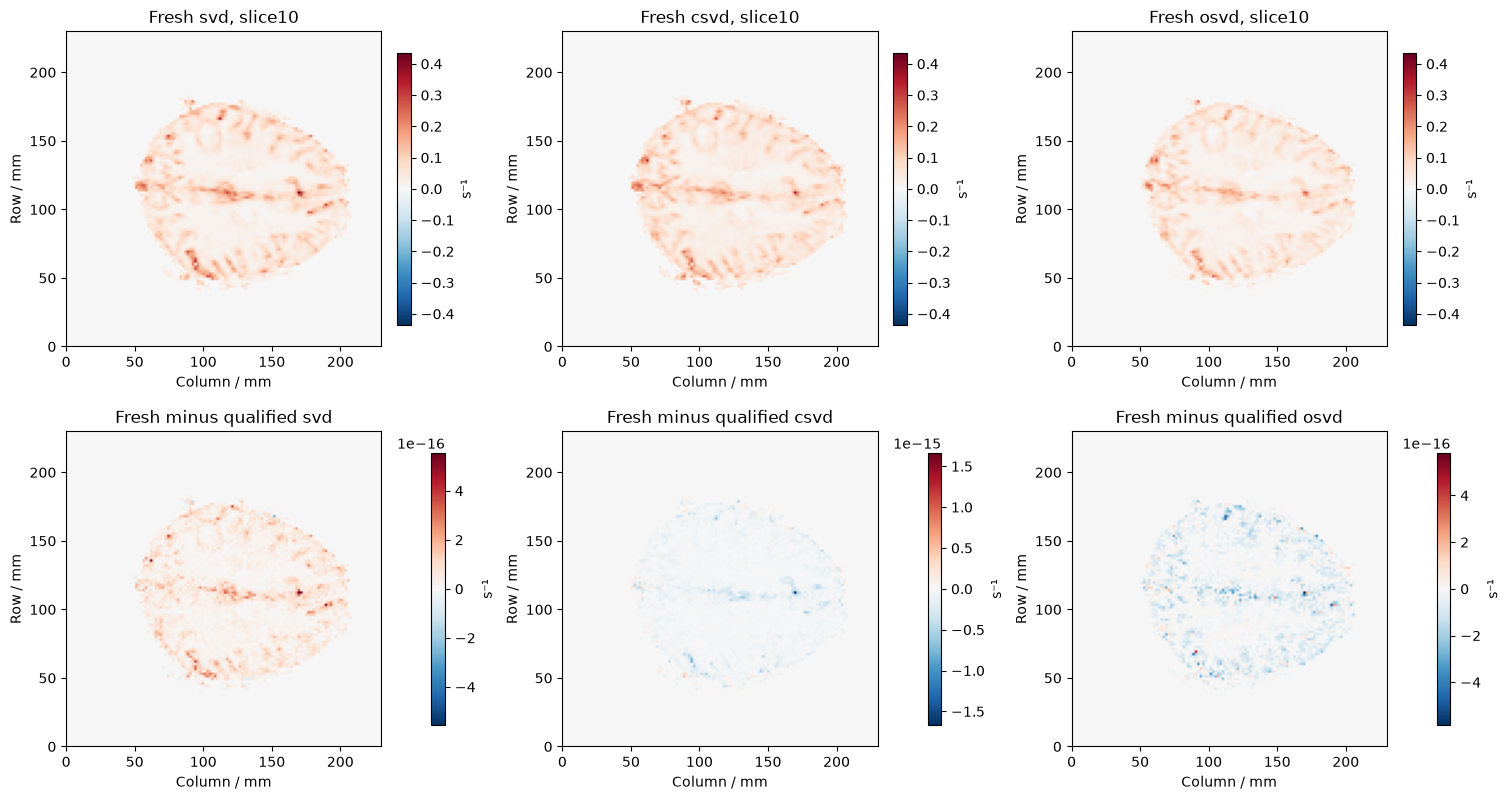

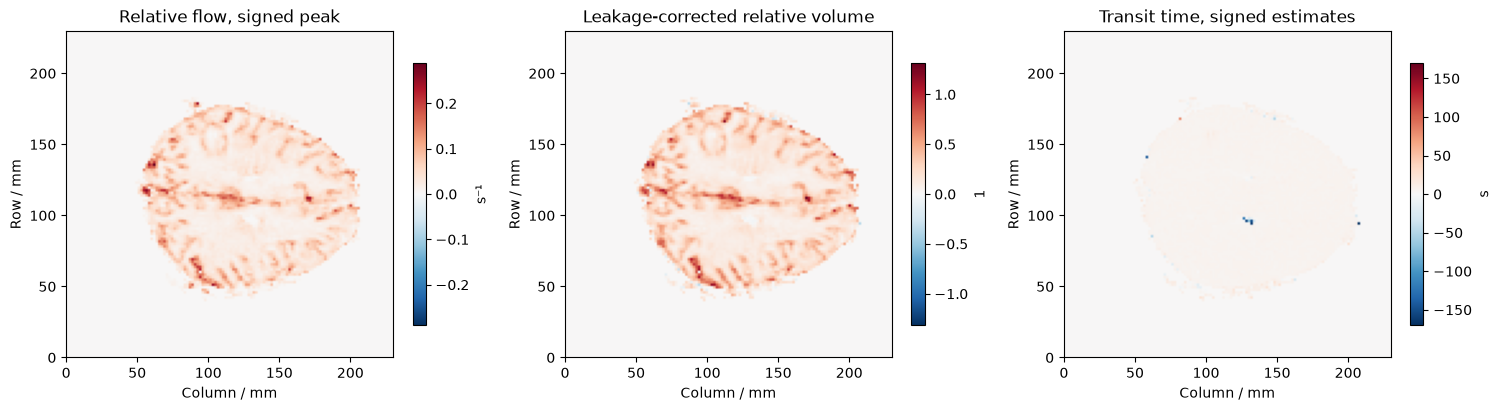

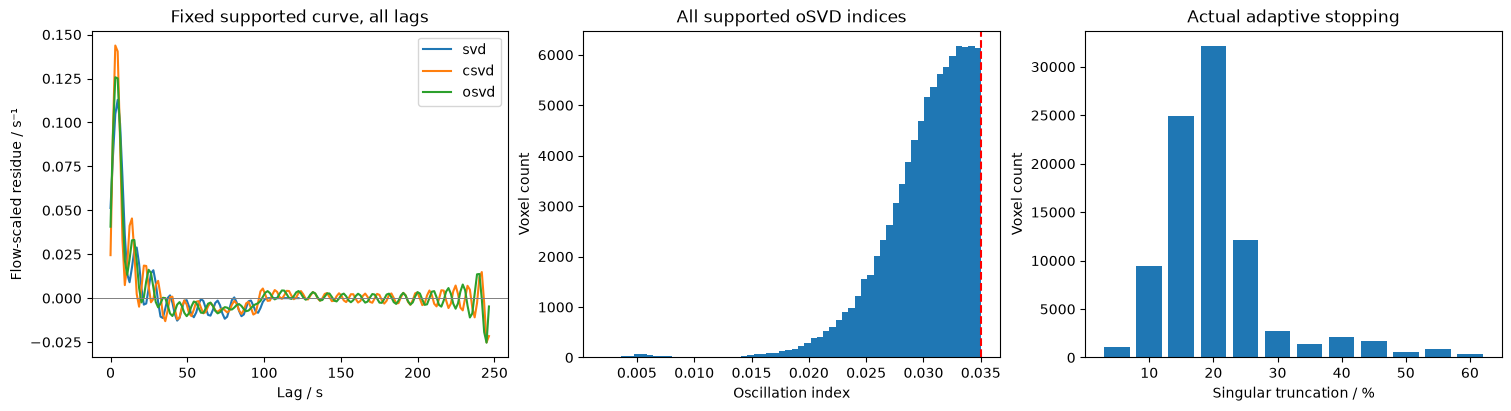

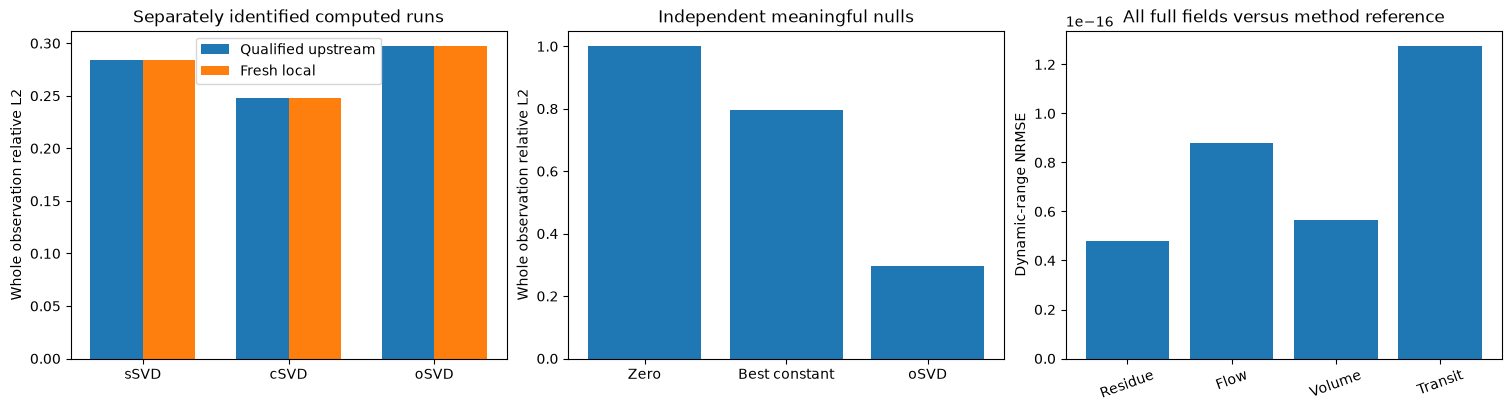

In [3]:
with np.load('notebooks/reference_outputs/upstream_maps.npz',allow_pickle=False) as z: upstream={k:z[k] for k in z.files}
whole_comparison={}
for method,current_flow in maps.items():
    source_flow=upstream[method+'_flow'][0];source_transit=upstream[method+'_transit'][0]
    fresh_transit=np.divide(volume,current_flow,out=np.zeros_like(volume),where=support)
    whole_comparison[method+'_flow']=float(np.sqrt(np.mean((current_flow-source_flow)**2))/np.ptp(source_flow))
    whole_comparison[method+'_transit']=float(np.sqrt(np.mean((fresh_transit-source_transit)**2))/np.ptp(source_transit))
for name,current in [('leakage_volume',volume),('uncorrected_volume',diagnostics['volume']['cbv'])]:
    reference=upstream[name][0];whole_comparison[name]=float(np.sqrt(np.mean((current-reference)**2))/np.ptp(reference))
print('Whole-volume original versus fresh comparison table (dynamic-range NRMSE):',json.dumps(whole_comparison,indent=2))
fig,ax=plt.subplots(2,3,figsize=(15,8),layout='constrained')
limit=max(np.max(abs(v[10])) for v in maps.values())
for j,method in enumerate(['svd','csvd','osvd']):
    image_panel(ax[0,j],maps[method][10],f'Fresh {method}, slice10','s⁻¹',True,limit)
    difference=maps[method][10]-upstream[method+'_flow'][0,10]
    image_panel(ax[1,j],difference,f'Fresh minus qualified {method}','s⁻¹',True)
records.append(export_figure(fig,FIG,'figure03_method_comparison',dict(**{k:v[10] for k,v in maps.items()},**{k+'_upstream':upstream[k+'_flow'][0,10] for k in maps},whole_comparison_nrmse=np.array(list(whole_comparison.values()))),'Fresh complete sSVD/cSVD/oSVD; matched flow scales, separately scaled signed numerical differences. Numeric source also identifies the whole-volume8quantity comparison table printed above.'));plt.show()
fig,ax=plt.subplots(1,3,figsize=(15,4),layout='constrained')
image_panel(ax[0],flow[10],'Relative flow, signed peak','s⁻¹',True)
image_panel(ax[1],volume[10],'Leakage-corrected relative volume','1',True)
image_panel(ax[2],transit[10],'Transit time, signed estimates','s',True)
records.append(export_figure(fig,FIG,'figure04_required_fields',dict(flow=flow[10],volume=volume[10],transit=transit[10]),'All required quantities scored; negative relative volume/time retained, not interpreted as valid negative physiology.'));plt.show()
fig,ax=plt.subplots(1,3,figsize=(15,4),layout='constrained')
lag=np.arange(160)*1.55
for method in curves:
    x=np.arange(curves[method].shape[-1])*1.55;ax[0].plot(x,curves[method][3],label=method)
ax[0].axhline(0,color='gray',lw=.7);ax[0].legend();ax[0].set(xlabel='Lag / s',ylabel='Flow-scaled residue / s⁻¹',title='Fixed supported curve, all lags')
ax[1].hist(oi,bins=60);ax[1].axvline(.035,color='red',ls='--');ax[1].set(xlabel='Oscillation index',ylabel='Voxel count',title='All supported oSVD indices')
values,counts=np.unique(cutoffs,return_counts=True);ax[2].bar(values*100,counts,width=4);ax[2].set(xlabel='Singular truncation / %',ylabel='Voxel count',title='Actual adaptive stopping')
records.append(export_figure(fig,FIG,'figure05_residue_and_truncation',dict(**curves,oi=oi,cutoff=cutoffs,coordinates=coordinates[probes]),'Complete lag curves and adaptive truncation; signed oscillations remain visible.'));plt.show()
fig,ax=plt.subplots(1,3,figsize=(15,4),layout='constrained')
source_errors=np.array([.28411153963729063,.24828614382379033,.2970902098755342])
fresh_errors=np.array([forward_errors[k] for k in ['svd','csvd','osvd']]);x=np.arange(3)
ax[0].bar(x-.18,source_errors,.36,label='Qualified upstream');ax[0].bar(x+.18,fresh_errors,.36,label='Fresh local');ax[0].set_xticks(x,['sSVD','cSVD','oSVD']);ax[0].set(ylabel='Whole observation relative L2',title='Separately identified computed runs');ax[0].legend()
names=['Zero','Best constant','oSVD'];values=[1,.794398454618137,forward_errors['osvd']];ax[1].bar(names,values);ax[1].set(ylabel='Whole observation relative L2',title='Independent meaningful nulls')
metric_keys=[k for k in report['metrics'] if k.endswith('_nrmse')];ax[2].bar(np.arange(4),[report['metrics'][k] for k in metric_keys]);ax[2].set_xticks(np.arange(4),['Residue','Flow','Volume','Transit'],rotation=20);ax[2].set(ylabel='Dynamic-range NRMSE',title='All full fields versus method reference')
records.append(export_figure(fig,FIG,'figure06_metrics_and_nulls',dict(source_errors=source_errors,fresh_errors=fresh_errors,null_errors=np.array(values),field_nrmse=np.array([report['metrics'][k] for k in metric_keys])),'Same metric/reference/whole-domain normalization; null control computed independently before local extraction.'));plt.show()


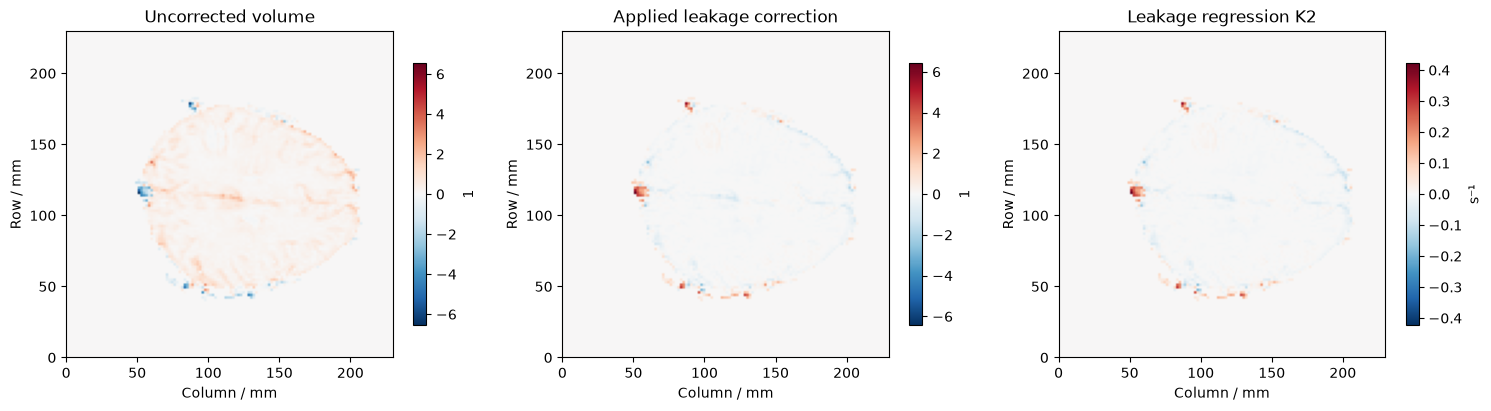

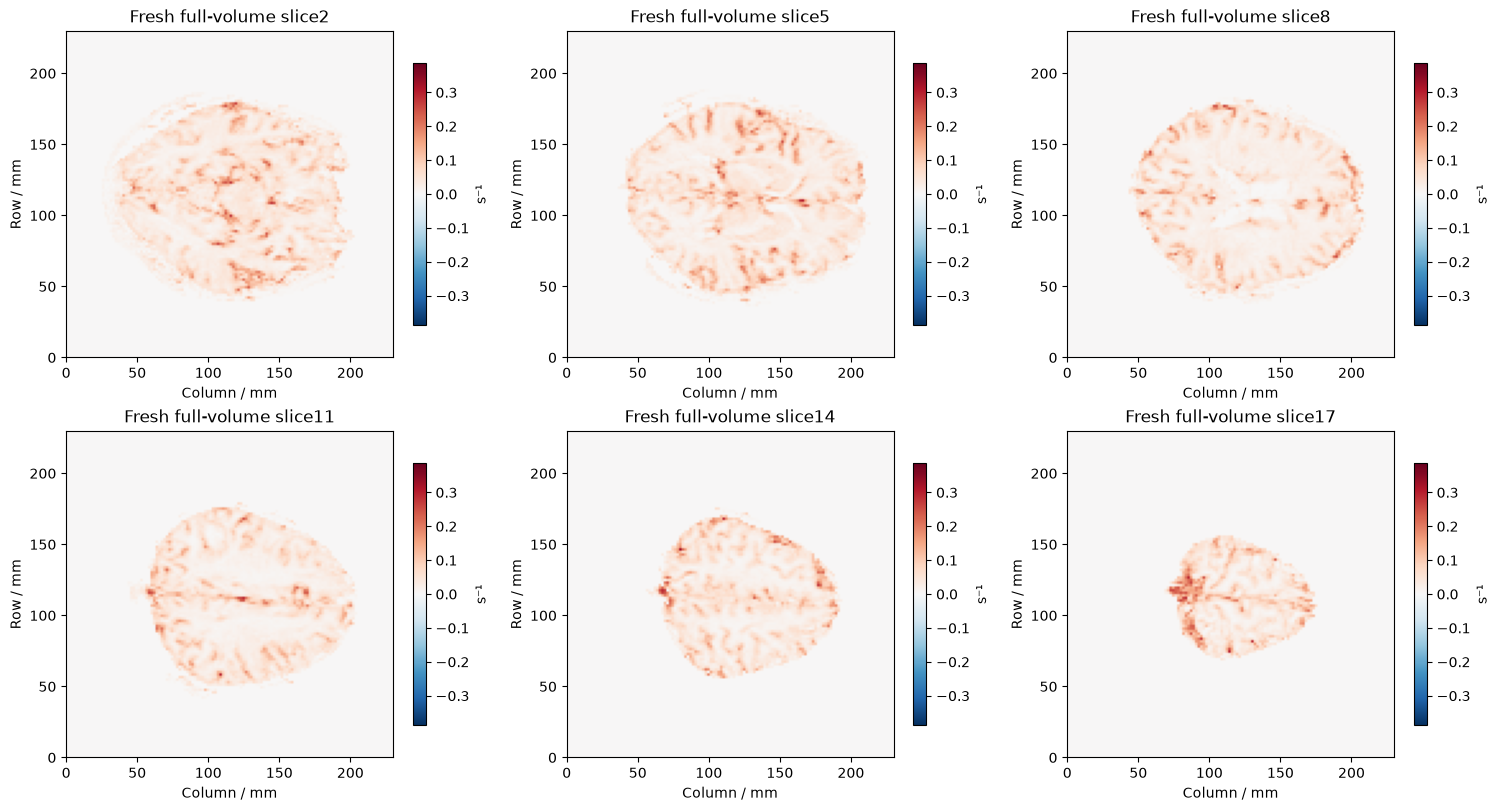

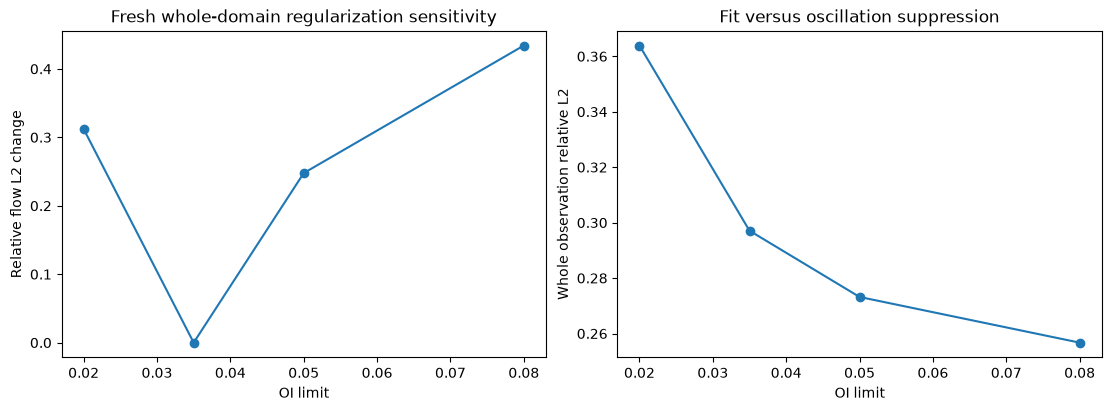

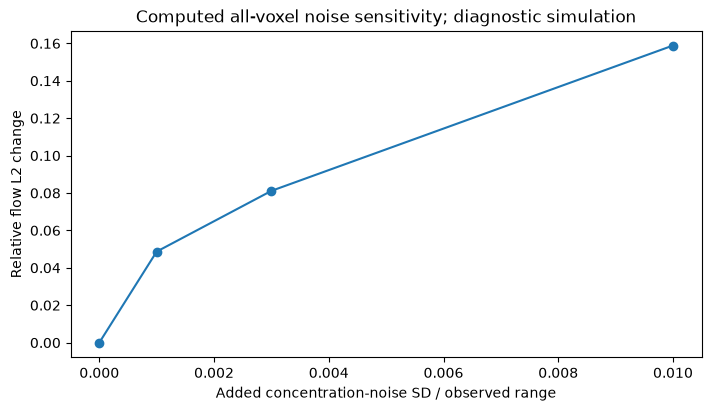

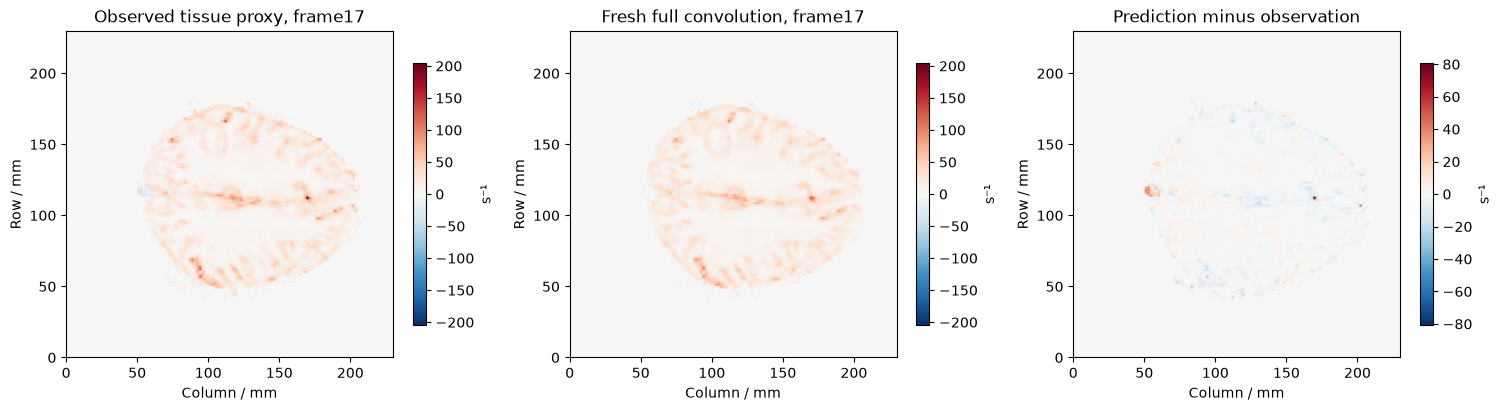

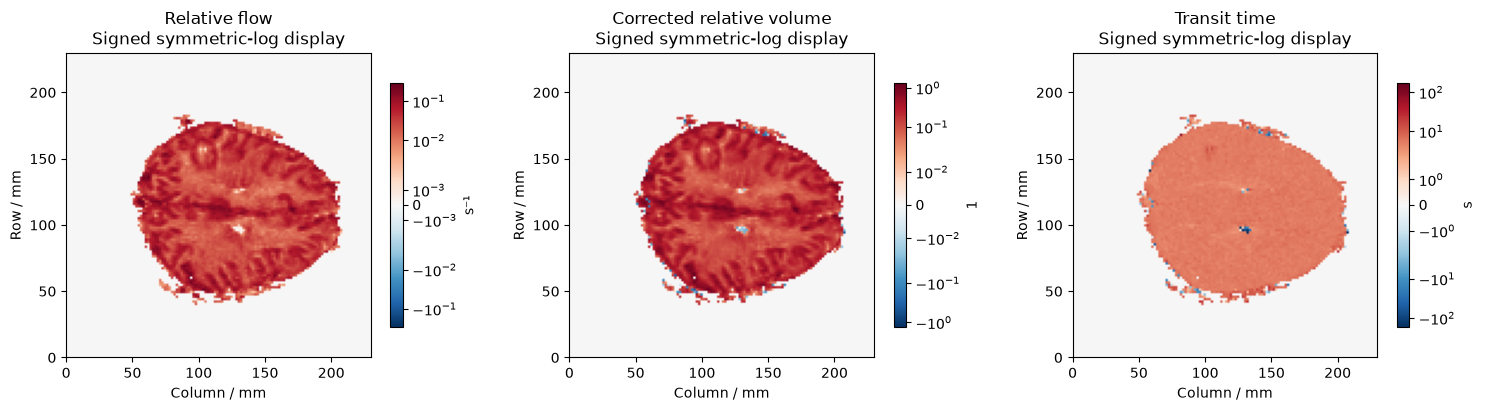

Exported actual figure groups: 12 negative supported volume: 2164 negative time: 2164


In [4]:
fig,ax=plt.subplots(1,3,figsize=(15,4),layout='constrained')
image_panel(ax[0],diagnostics['volume']['cbv'][10],'Uncorrected volume','1',True)
image_panel(ax[1],volume[10]-diagnostics['volume']['cbv'][10],'Applied leakage correction','1',True)
image_panel(ax[2],diagnostics['volume']['K2'][10],'Leakage regression K2','s⁻¹',True)
records.append(export_figure(fig,FIG,'figure07_leakage',dict(uncorrected=diagnostics['volume']['cbv'][10],corrected=volume[10],K2=diagnostics['volume']['K2'][10],K2cv=diagnostics['volume']['K2cv'][10]),'Original conditional CV correction; no claim of external permeability truth.'));plt.show()
fig,ax=plt.subplots(2,3,figsize=(15,8),layout='constrained')
for axis,z in zip(ax.ravel(),[2,5,8,11,14,17]):image_panel(axis,flow[z],f'Fresh full-volume slice{z}','s⁻¹',True,float(np.max(abs(flow))))
records.append(export_figure(fig,FIG,'figure08_full_volume',dict(flow=flow,slice_indices=np.array([2,5,8,11,14,17])),'Six fixed slices of the actively reconstructed whole22-slice volume; shared full-volume scale.'));plt.show()
thresholds=[.02,.035,.05,.08];sensitivity=[];oi_forward=[]
for limit in thresholds:
    result=deconvolve(y,a,oi_limit=limit);sensitivity.append(float(np.linalg.norm(result['map']-flow[support])/np.linalg.norm(flow[support])))
    oi_forward.append(float(np.linalg.norm(forward(result['residual'],a)-y)/np.linalg.norm(y)))
del result;gc.collect()
fig,ax=plt.subplots(1,2,figsize=(11,4),layout='constrained');ax[0].plot(thresholds,sensitivity,'o-');ax[0].set(xlabel='OI limit',ylabel='Relative flow L2 change',title='Fresh whole-domain regularization sensitivity');ax[1].plot(thresholds,oi_forward,'o-');ax[1].set(xlabel='OI limit',ylabel='Whole observation relative L2',title='Fit versus oscillation suppression')
records.append(export_figure(fig,FIG,'figure09_oi_sensitivity',dict(thresholds=np.array(thresholds),flow_changes=np.array(sensitivity),forward_error=np.array(oi_forward)),'Every OI setting actually reconstructs every supported voxel; bound .035 fixed before extraction.'));plt.show()
noise_levels=[0,.001,.003,.01];changes=[]
for level in noise_levels:
    noisy=perturb_concentration(y,level,124);result=deconvolve(noisy,a);changes.append(float(np.linalg.norm(result['map']-flow[support])/np.linalg.norm(flow[support])))
del result,noisy;gc.collect()
fig,ax=plt.subplots(figsize=(7,4),layout='constrained');ax.plot(noise_levels,changes,'o-');ax.set(xlabel='Added concentration-noise SD / observed range',ylabel='Relative flow L2 change',title='Computed all-voxel noise sensitivity; diagnostic simulation')
records.append(export_figure(fig,FIG,'figure10_noise_sensitivity',dict(noise_levels=np.array(noise_levels),flow_changes=np.array(changes),seed=np.array([124])),'Synthetic proxy-noise diagnostics, explicitly separate from bound real raw observations and true accuracy.'));plt.show()
fig,ax=plt.subplots(1,3,figsize=(15,4),layout='constrained')
limit=max(float(np.max(abs(observed_frame[10]))),float(np.max(abs(predicted_frame[10]))))
image_panel(ax[0],observed_frame[10],'Observed tissue proxy, frame17','s⁻¹',True,limit)
image_panel(ax[1],predicted_frame[10],'Fresh full convolution, frame17','s⁻¹',True,limit)
image_panel(ax[2],predicted_frame[10]-observed_frame[10],'Prediction minus observation','s⁻¹',True)
records.append(export_figure(fig,FIG,'figure11_observed_model_residual',dict(observed=observed_frame[10],predicted=predicted_frame[10],residual=predicted_frame[10]-observed_frame[10],all_voxel_temporal_rms=residual_rms),'Actively predicted real observations, paired common scales and signed residuals; all supported voxels/times enter the numeric metric.'));plt.show()
from matplotlib.colors import SymLogNorm
fig,ax=plt.subplots(1,3,figsize=(15,4),layout='constrained')
for axis,values,title,unit in zip(ax,[flow[10],volume[10],transit[10]],['Relative flow','Corrected relative volume','Transit time'],['s⁻¹','1','s']):
    bound=float(np.max(abs(values)));norm=SymLogNorm(linthresh=bound/100,vmin=-bound,vmax=bound,base=10)
    artist=axis.imshow(values,origin='lower',extent=[0,128*1.796875,0,128*1.796875],cmap='RdBu_r',norm=norm)
    axis.set(xlabel='Column / mm',ylabel='Row / mm',title=title+'\nSigned symmetric-log display');fig.colorbar(artist,ax=axis,label=unit,shrink=.8)
records.append(export_figure(fig,FIG,'figure12_full_range_signed_display',dict(flow=flow[10],volume=volume[10],transit=transit[10]),'Supplementary explicitly nonlinear symmetric-log color display; full minima/maxima retained with linear region1%of largest absolute value. Linear scientific maps remain Figure4. No scoring or data change.'));plt.show()
(FIG/'figure_index.json').write_text(json.dumps(dict(figures=records),indent=2),encoding='utf8')
print('Exported actual figure groups:',len(records),'negative supported volume:',int(np.sum(volume[support]<0)),'negative time:',int(np.sum(transit[support]<0)))


## Conclusion
The complete local oSVD path actively reconstructed all89588 supported voxels and160lags, alongside fresh sSVD/cSVD controls. All four required arrays pass frozen original-method parity and independent whole-observation evaluation. The leakage, truncation, noise and six-slice comparisons were computed during execution.

These are conditional relative estimates. Approximately30% whole tissue-curve residual remains; recirculation, arterial sampling, noise and leakage violate ideal tracer assumptions. Negative regularization lobes, negative corrected volumes and negative transit estimates are retained as visible model/measurement limitations, not described as physiological truth. Absolute flow/volume calibration, diagnosis and external patient truth are unavailable. Numerical agreement with a qualified source establishes extraction fidelity, not clinical accuracy. The original two-line defect correction and unexplained prior native crashes remain documented separately from actual successful complete runs.
